<a href="https://colab.research.google.com/github/ArtemFirst1/DataLoves_homework/blob/main/%22HW_2_1_%D0%9F%D0%BE%D0%B1%D1%83%D0%B4%D0%BE%D0%B2%D0%B0_%D0%BB%D1%96%D0%BD%D1%96%D0%B9%D0%BD%D0%BE%D1%97_%D1%80%D0%B5%D0%B3%D1%80%D0%B5%D1%81%D1%96%D1%97_%D0%B7%D0%B0_%D0%BE%D0%B4%D0%BD%D0%BE%D1%8E_%D0%BE%D0%B7%D0%BD%D0%B0%D0%BA%D0%BE%D1%8E_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

В цьому домашньому завданні кожне завдання оцінюється по 10 балів.

 **Завдання 1.** Після перегляду лекцій про поняття функії, вступ до лінійної алгебри і мат. формулювання лін. регресії знайдіть найкращу лінію для прогнозу `charges` за `age` **для некурців** (датафрейм `non_smoker_df`) з допомогою

1. Методу МНК (з використанням тільки `numpy`, без `scikit learn`)

2. Full-Batch градієнтного спуску з `numpy` . Протестуйте 3 різних learning rate і зробіть висновок, який є найкращим виходячи з практик для цього, наведених в лекції. Зверніть увагу, що на вхід треба набір даних дворозміний, для цього можливо треба буде трансформувати Ваші дані X в формат, як був в лекції "Математичне формулювання лінійної регресії". Також, градієнтний спуск в нашому випадку може розходитись з навчальним рейтом 0.1, бо цей рейт в цій задачі завеликий. Спробуйте нижчі рейти.
3. З `scikit-learn.LinearRegression`. Тут зверніть увагу, що вхід `X` має бути двовимірним масивом, тому нам потрібно передати dataframe, а не окрему колонку. Якщо у Вас X - колонка (а у Вас так мало б бути), то можна скористатись `X.to_frame()` щоб конвертувати колонку в датафрейм.

Для кожного методу
- знайдіть і виведіть коефіцієнти моделі
- обчисліть прогнози моделі і збережіть в окрему змінну
- порахуйте точність прогнозу RMSE  

Для градієнтного спуску виведіть графік помилки в залежності від ітерації.

А також побудуйте на одному графіку дані `age` проти `charges` в вигляді діаграми розсіювання і всі три лінії регресії, знайдені кожним з методів (для град. спуску оберіть варіант з тим learning rate, який виявився найкращим).

Зробіть висновки, чи відрізняються результати моделей?
Чи є знайдены параметри моделы близькими до ваших найкращих припущень?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [2]:
medical_df = pd.read_csv('/content/medical-charges.csv')
non_smoker_df = medical_df[medical_df.smoker == 'no']

# 1. Метод МНК

In [3]:
X = non_smoker_df['age'].to_numpy()
y = non_smoker_df['charges'].to_numpy()

# Додаємо стовпець одиниць для вільного коефіцієнта b
X_matrix = np.column_stack((X, np.ones(len(X))))
w_mnk, b_mnk = np.linalg.lstsq(X_matrix, y, rcond=None)[0]

pred_mnk = w_mnk * X + b_mnk
rmse_mnk = np.sqrt(np.mean((y - pred_mnk)**2))

print('Кількість некурців:', len(X))
print('w =', round(w_mnk, 4))
print('b =', round(b_mnk, 4))
print('RMSE =', round(rmse_mnk, 4))

Кількість некурців: 1064
w = 267.2489
b = -2091.4206
RMSE = 4662.5058


# 2. Full-Batch градієнтний спуск

Learning rate: 0.0001
w = 48.4484
b = -379.1445
RMSE = 8883.0167

Learning rate: 0.001
w = 231.1531
b = -1808.9438
RMSE = 4826.4737

Learning rate: 0.01
w = 267.2489
b = -2091.4206
RMSE = 4662.5058

Найкращий learning rate: 0.01
Найкращий RMSE: 4662.5058


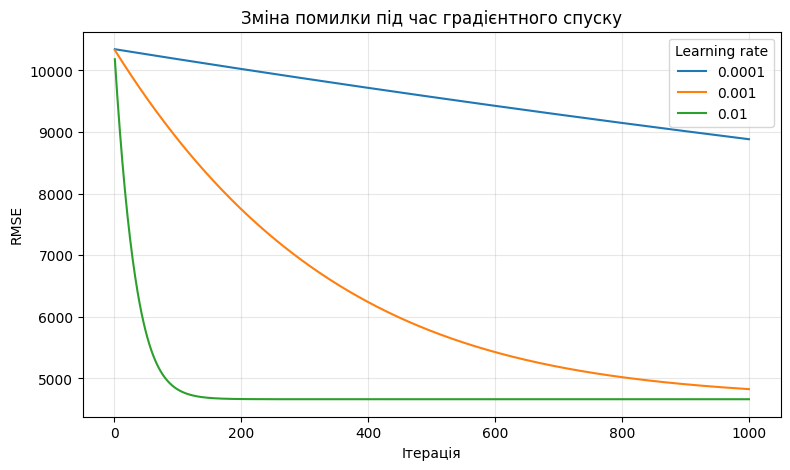

In [4]:
# Масштабуємо вік, щоб градієнтний спуск був стабільним
age_mean = X.mean()
age_std = X.std()
X_scaled = (X - age_mean) / age_std
X_gd = np.column_stack((X_scaled, np.ones(len(X))))

learning_rates = [0.0001, 0.001, 0.01]
iterations = 1000
best_rmse = float('inf')

plt.figure(figsize=(9, 5))

for lr in learning_rates:
    weights = np.zeros(2)
    errors = []

    for i in range(iterations):
        pred = X_gd @ weights
        error = pred - y
        gradient = 2 * X_gd.T @ error / len(y)
        weights = weights - lr * gradient

        rmse = np.sqrt(np.mean((y - X_gd @ weights)**2))
        errors.append(rmse)

    # Повертаємо коефіцієнти до початкового масштабу віку
    w = weights[0] / age_std
    b = weights[1] - w * age_mean
    pred = w * X + b
    rmse = np.sqrt(np.mean((y - pred)**2))

    print('Learning rate:', lr)
    print('w =', round(w, 4))
    print('b =', round(b, 4))
    print('RMSE =', round(rmse, 4))
    print()

    plt.plot(range(1, iterations + 1), errors, label=str(lr))

    if rmse < best_rmse:
        best_rmse = rmse
        best_lr = lr
        w_gd = w
        b_gd = b
        pred_gd = pred.copy()

rmse_gd = best_rmse
print('Найкращий learning rate:', best_lr)
print('Найкращий RMSE:', round(rmse_gd, 4))

plt.xlabel('Ітерація')
plt.ylabel('RMSE')
plt.title('Зміна помилки під час градієнтного спуску')
plt.legend(title='Learning rate')
plt.grid(alpha=0.3)
plt.show()

# 3. Лінійна регресія з використанням sklearn

In [5]:
model = LinearRegression()
model.fit(non_smoker_df[['age']], y)

w_sklearn = model.coef_[0]
b_sklearn = model.intercept_
pred_sklearn = model.predict(non_smoker_df[['age']])
rmse_sklearn = np.sqrt(np.mean((y - pred_sklearn)**2))

print('w =', round(w_sklearn, 4))
print('b =', round(b_sklearn, 4))
print('RMSE =', round(rmse_sklearn, 4))

w = 267.2489
b = -2091.4206
RMSE = 4662.5058


# Порівняння трьох методів

,Метод,w,b,RMSE
0,МНК,267.2489,-2091.4206,4662.5058
1,Градієнтний спуск,267.2489,-2091.4206,4662.5058
2,sklearn,267.2489,-2091.4206,4662.5058


RMSE попереднього підбору: 4662.5074


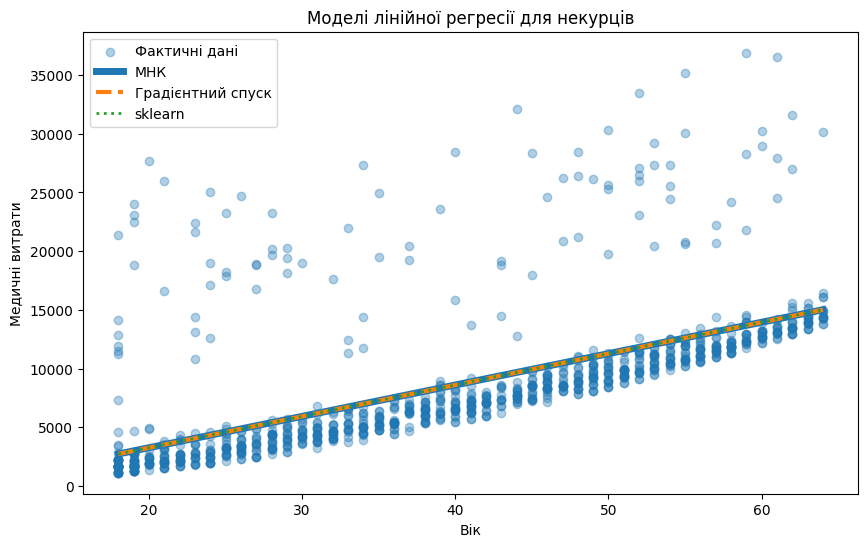

In [6]:
results = pd.DataFrame({
    'Метод': ['МНК', 'Градієнтний спуск', 'sklearn'],
    'w': [w_mnk, w_gd, w_sklearn],
    'b': [b_mnk, b_gd, b_sklearn],
    'RMSE': [rmse_mnk, rmse_gd, rmse_sklearn]
})
display(results.round(4))

# Порівняння з параметрами, підібраними в попередньому ДЗ
w_previous = 267
b_previous = -2080
rmse_previous = np.sqrt(np.mean((y - (w_previous * X + b_previous))**2))
print('RMSE попереднього підбору:', round(rmse_previous, 4))

age_line = np.linspace(X.min(), X.max(), 100)
plt.figure(figsize=(10, 6))
plt.scatter(X, y, alpha=0.35, label='Фактичні дані')
plt.plot(age_line, w_mnk * age_line + b_mnk, label='МНК', linewidth=5)
plt.plot(age_line, w_gd * age_line + b_gd, '--', label='Градієнтний спуск', linewidth=3)
plt.plot(age_line, w_sklearn * age_line + b_sklearn, ':', label='sklearn', linewidth=2)
plt.xlabel('Вік')
plt.ylabel('Медичні витрати')
plt.title('Моделі лінійної регресії для некурців')
plt.legend()
plt.show()

**Висновок**: Усі три методи дали практично однакові коефіцієнти: w = 267,25 та b = −2091,42, а RMSE становить 4662,51. На графіку видно, що три лінії регресії майже повністю збігаються. Для градієнтного спуску найкращим серед трьох перевірених значень став learning rate = 0.01, оскільки помилка зменшувалася найшвидше. Отримані коефіцієнти близькі до підібраних у попередньому завданні (w = 267, b = −2080). При цьому для окремих людей фактичні витрати значно відрізняються від прогнозу.

 **Завдання 2.** Навчіть модель лінійної регресії з допомогою sklearn оцінювати розмір медичних збори для **курців** за їх віком.
Виведіть
- точність моделі
-  коефіцієнти
-  візуалізуйте модель у вигляді лінії на графіку розсіювання `age` проти `charges`

і зробіть висновки, чи це хороша модель, чи ви б її використовували в компанії?

Кількість курців: 274
w = 305.2376
b = 20294.1281
RMSE = 10711.0
R² = 0.1356
Середні витрати: 32050.23


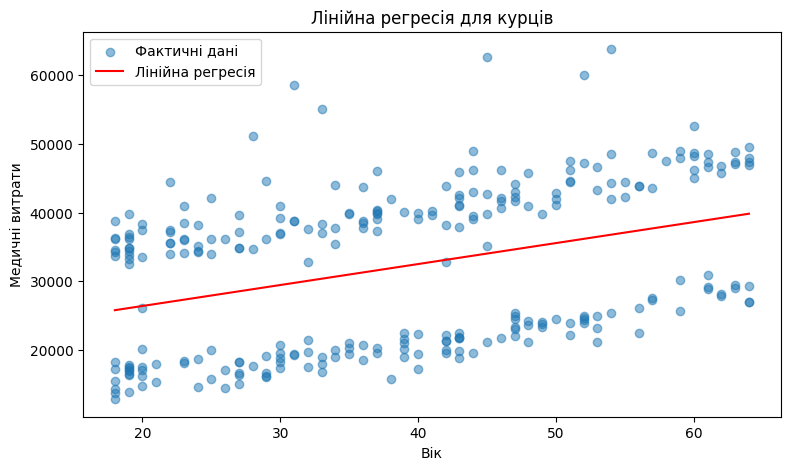

In [7]:
smoker_df = medical_df[medical_df.smoker == 'yes']
X_smoker = smoker_df[['age']]
y_smoker = smoker_df['charges']

model_smoker = LinearRegression()
model_smoker.fit(X_smoker, y_smoker)
pred_smoker = model_smoker.predict(X_smoker)

w_smoker = model_smoker.coef_[0]
b_smoker = model_smoker.intercept_
rmse_smoker = np.sqrt(np.mean((y_smoker - pred_smoker)**2))
r2_smoker = model_smoker.score(X_smoker, y_smoker)

print('Кількість курців:', len(smoker_df))
print('w =', round(w_smoker, 4))
print('b =', round(b_smoker, 4))
print('RMSE =', round(rmse_smoker, 2))
print('R² =', round(r2_smoker, 4))
print('Середні витрати:', round(y_smoker.mean(), 2))

age_line = np.linspace(X_smoker['age'].min(), X_smoker['age'].max(), 100)
plt.figure(figsize=(9, 5))
plt.scatter(X_smoker['age'], y_smoker, alpha=0.5, label='Фактичні дані')
plt.plot(age_line, w_smoker * age_line + b_smoker, color='red', label='Лінійна регресія')
plt.xlabel('Вік')
plt.ylabel('Медичні витрати')
plt.title('Лінійна регресія для курців')
plt.legend()
plt.show()

**Висновок**: Для курців коефіцієнти моделі становлять w = 305,24 та b = 20294,13. На графіку видно, що зі збільшенням віку витрати загалом зростають, але багато точок знаходяться далеко від лінії регресії. RMSE становить 10711,00, а R² = 0,1356, тобто вік пояснює лише близько 13,56% варіації витрат у цій вибірці. Я б не використовував цю модель у компанії як основну для прогнозування, оскільки її точність низька. Для покращення прогнозу варто додати інші ознаки, наприклад BMI та кількість дітей.